# 01 - Exploratory data analysis

Datasets: **Salminen et al. (2022)** - 40,432 Amazon reviews, GPT-2 fakes vs. human originals (main set) - and
**Ott et al. (2011/2013)** - 1,600 hotel reviews, MTurk-written fakes vs. truthful (cross-domain test set).

All plots are saved to `results/plots/eda/` at 300 dpi by `src/eda.py`; this notebook runs it and shows them.
The written observations are in `results/eda_summary.md`.

In [1]:
# Make `src` importable and run from the repo root (works locally and on Colab)
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
from IPython.display import Image, Markdown, display
from src.config import load_config
cfg = load_config()
print("repo root:", ROOT)

repo root: C:\Users\Admin\Projects\fake-review-detection


In [2]:
from src.data_loading import load_dataset
raw = load_dataset("salminen")
print(raw.shape); raw.head()

(40432, 9)


,review_id,text,label,rating,category,user_id,product_id,date,source_dataset
0,salminen_0,"Love this! Well made, sturdy, and very comfor...",1,5.0,Home_and_Kitchen,NaN,NaN,NaN,salminen
1,salminen_1,"love it, a great upgrade from the original. I...",1,5.0,Home_and_Kitchen,NaN,NaN,NaN,salminen
2,salminen_2,This pillow saved my back. I love the look and...,1,5.0,Home_and_Kitchen,NaN,NaN,NaN,salminen
3,salminen_3,"Missing information on how to use it, but it i...",1,1.0,Home_and_Kitchen,NaN,NaN,NaN,salminen
4,salminen_4,Very nice set. Good quality. We have had the s...,1,5.0,Home_and_Kitchen,NaN,NaN,NaN,salminen


In [3]:
raw["label"].value_counts().rename({0: "genuine (OR)", 1: "fake (CG)"})

label
fake (CG)       20216
genuine (OR)    20216
Name: count, dtype: int64

## Salminen (Amazon, GPT-2 fakes)

In [4]:
from src.eda import run_eda
import json
stats = run_eda("salminen", cfg)
print(json.dumps({k: stats[k] for k in ["n_reviews", "class_counts", "words_median", "words_mean",
                                          "share_over_64_words", "duplicate_text_rows", "share_ending_with_punctuation"]}, indent=1))

21:16:53 | INFO    | eda | saved results\plots\eda\salminen_class_balance.png


21:16:55 | INFO    | eda | saved results\plots\eda\salminen_length_by_class.png


21:16:56 | INFO    | eda | saved results\plots\eda\salminen_rating_by_class.png


21:16:57 | INFO    | eda | saved results\plots\eda\salminen_category_by_class.png


21:17:02 | INFO    | eda | saved results\plots\eda\salminen_top_unigrams.png


21:17:07 | INFO    | eda | saved results\plots\eda\salminen_top_bigrams.png


21:17:14 | INFO    | eda | saved results\plots\eda\salminen_wordclouds.png


21:17:23 | INFO    | eda | saved results\plots\eda\salminen_style_signals.png


{
 "n_reviews": 40432,
 "class_counts": {
  "fake": 20216,
  "genuine": 20216
 },
 "words_median": {
  "fake": 39.0,
  "genuine": 47.0
 },
 "words_mean": {
  "fake": 68.8,
  "genuine": 82.1
 },
 "share_over_64_words": 0.362,
 "duplicate_text_rows": 71,
 "share_ending_with_punctuation": {
  "fake": 0.352,
  "genuine": 0.906
 }
}


**class_balance**

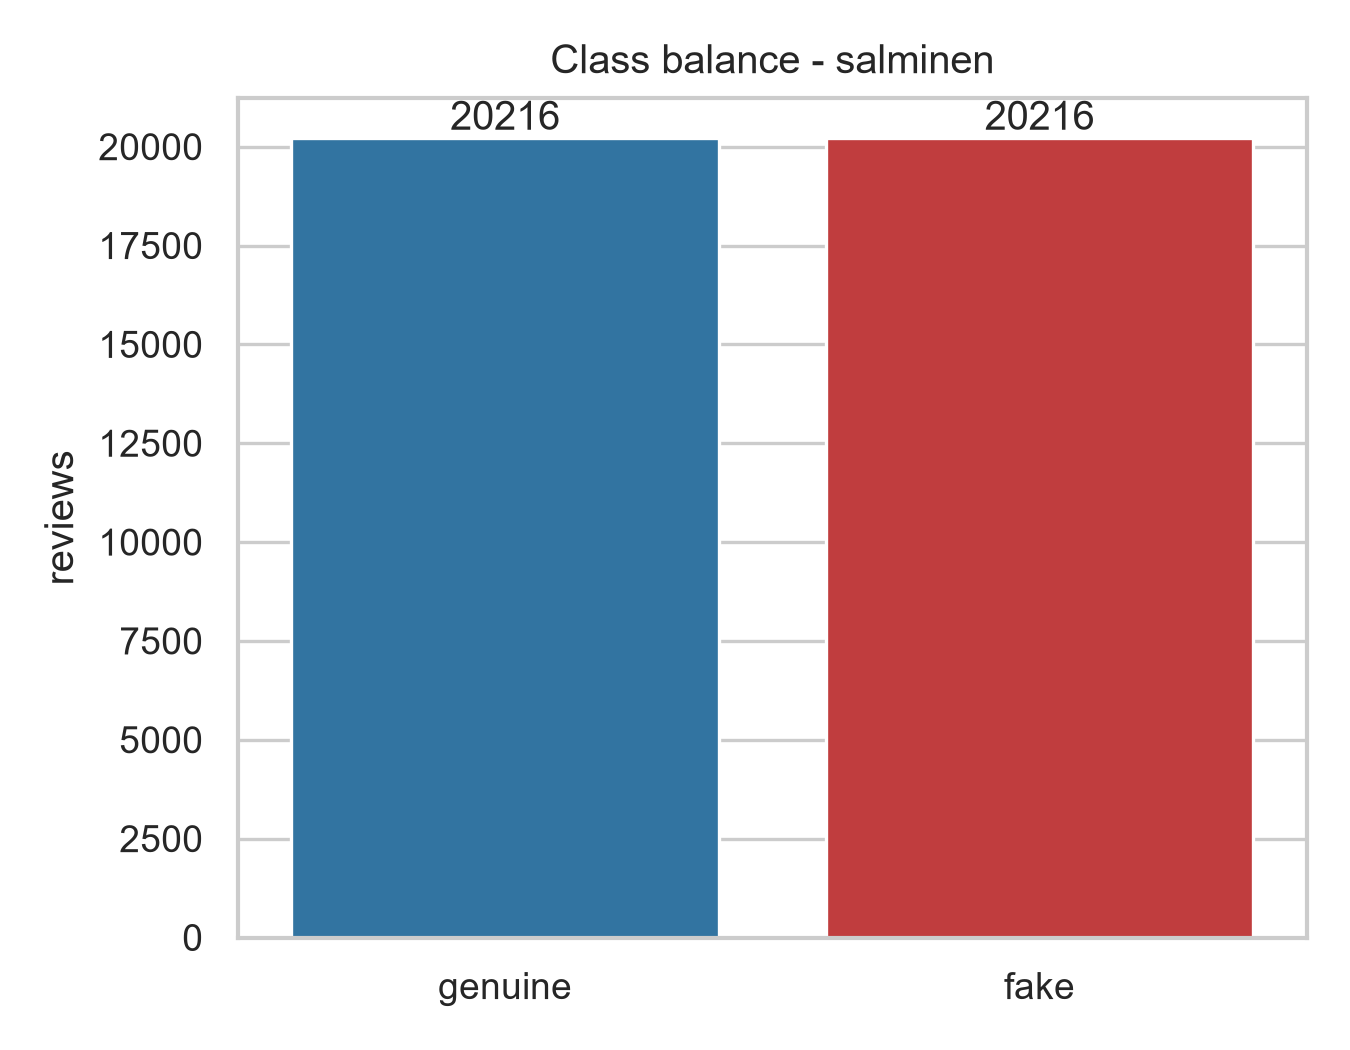

**length_by_class**

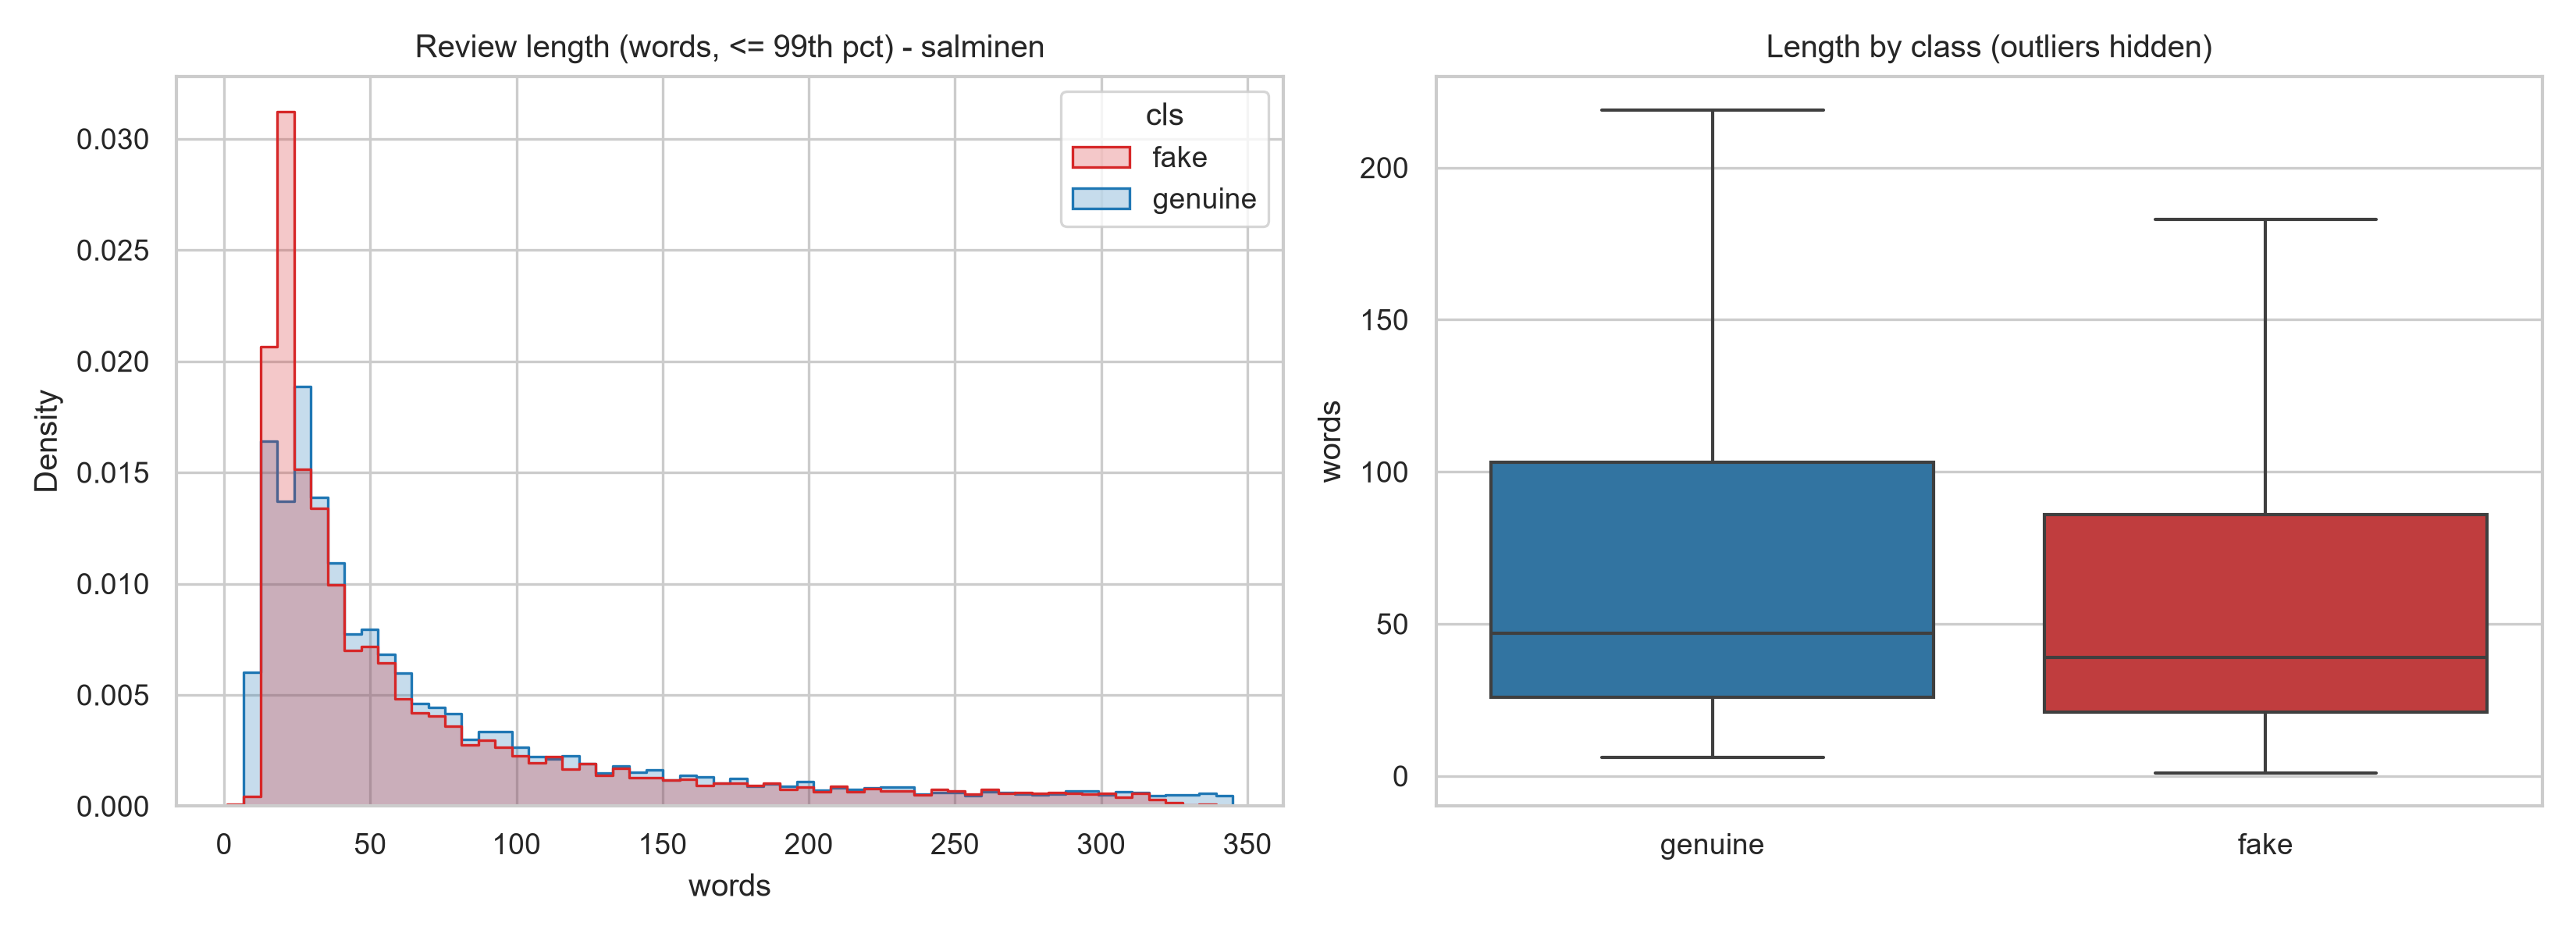

**rating_by_class**

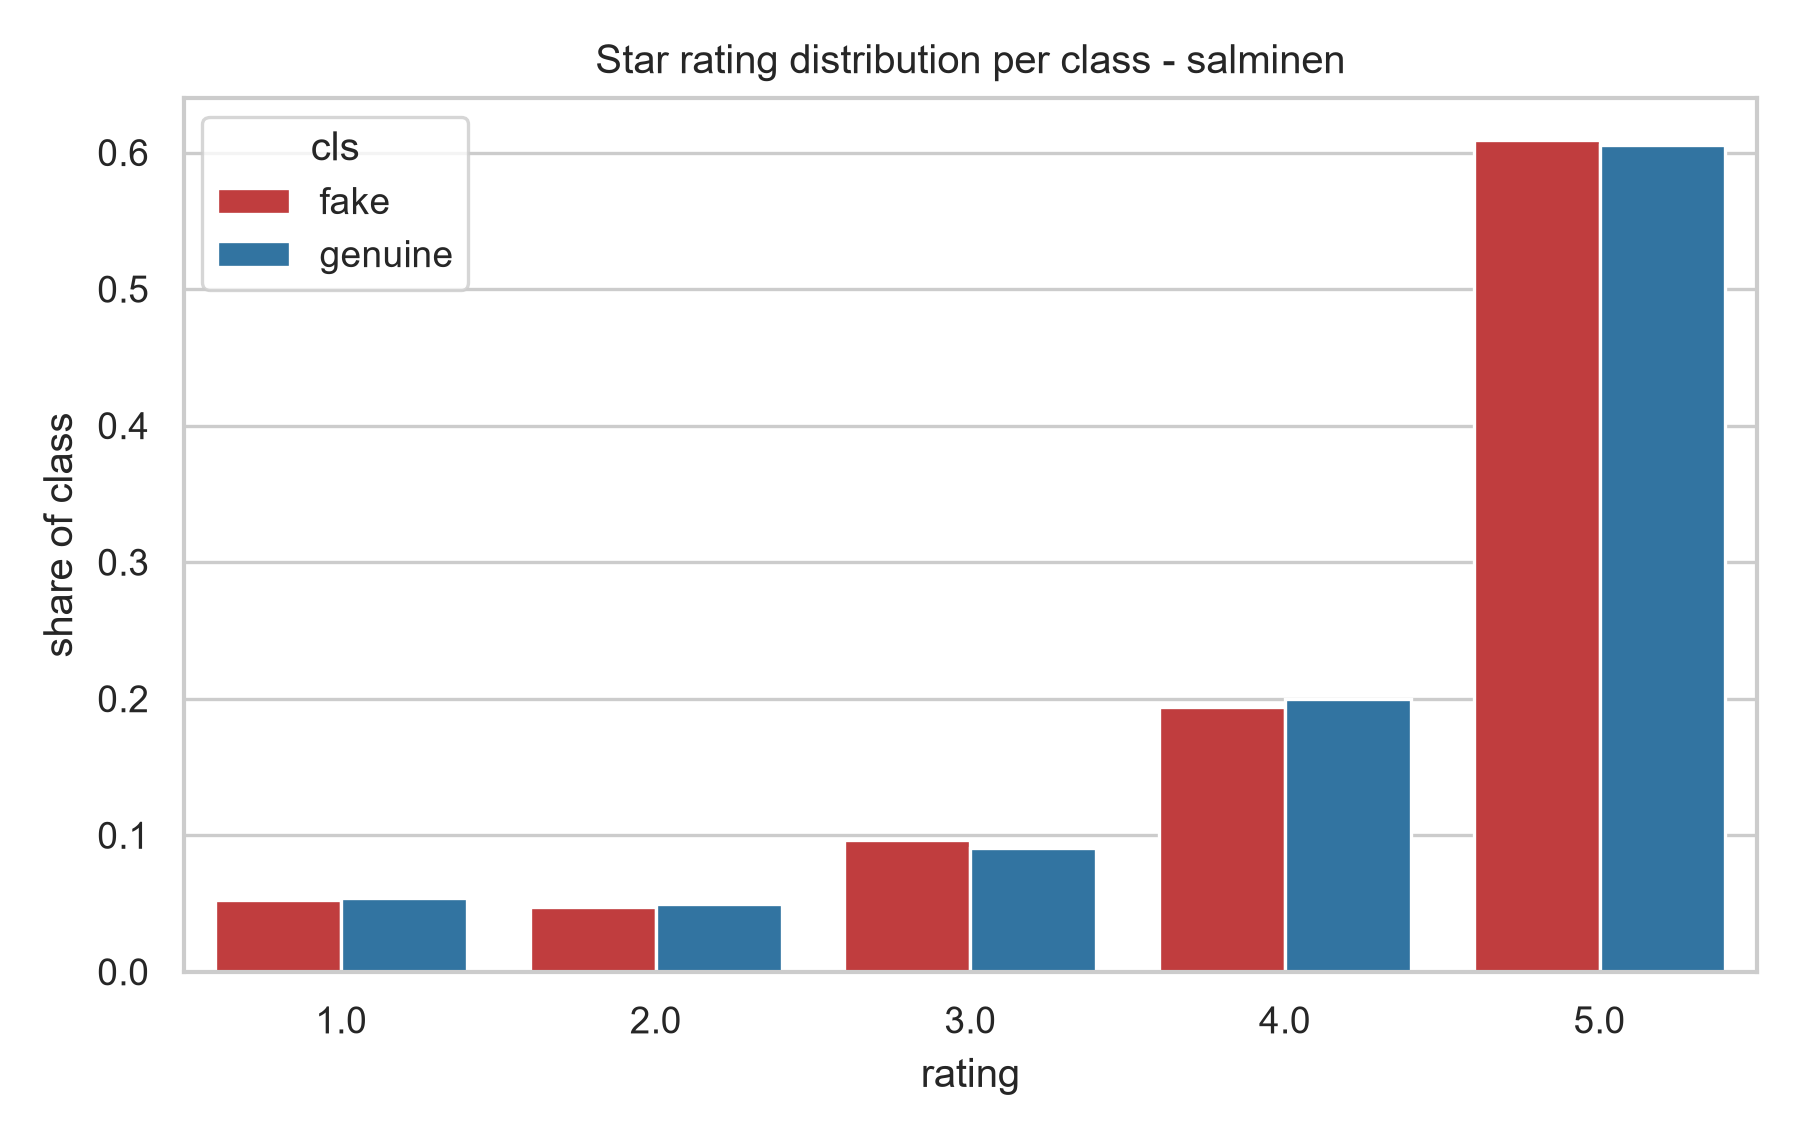

**category_by_class**

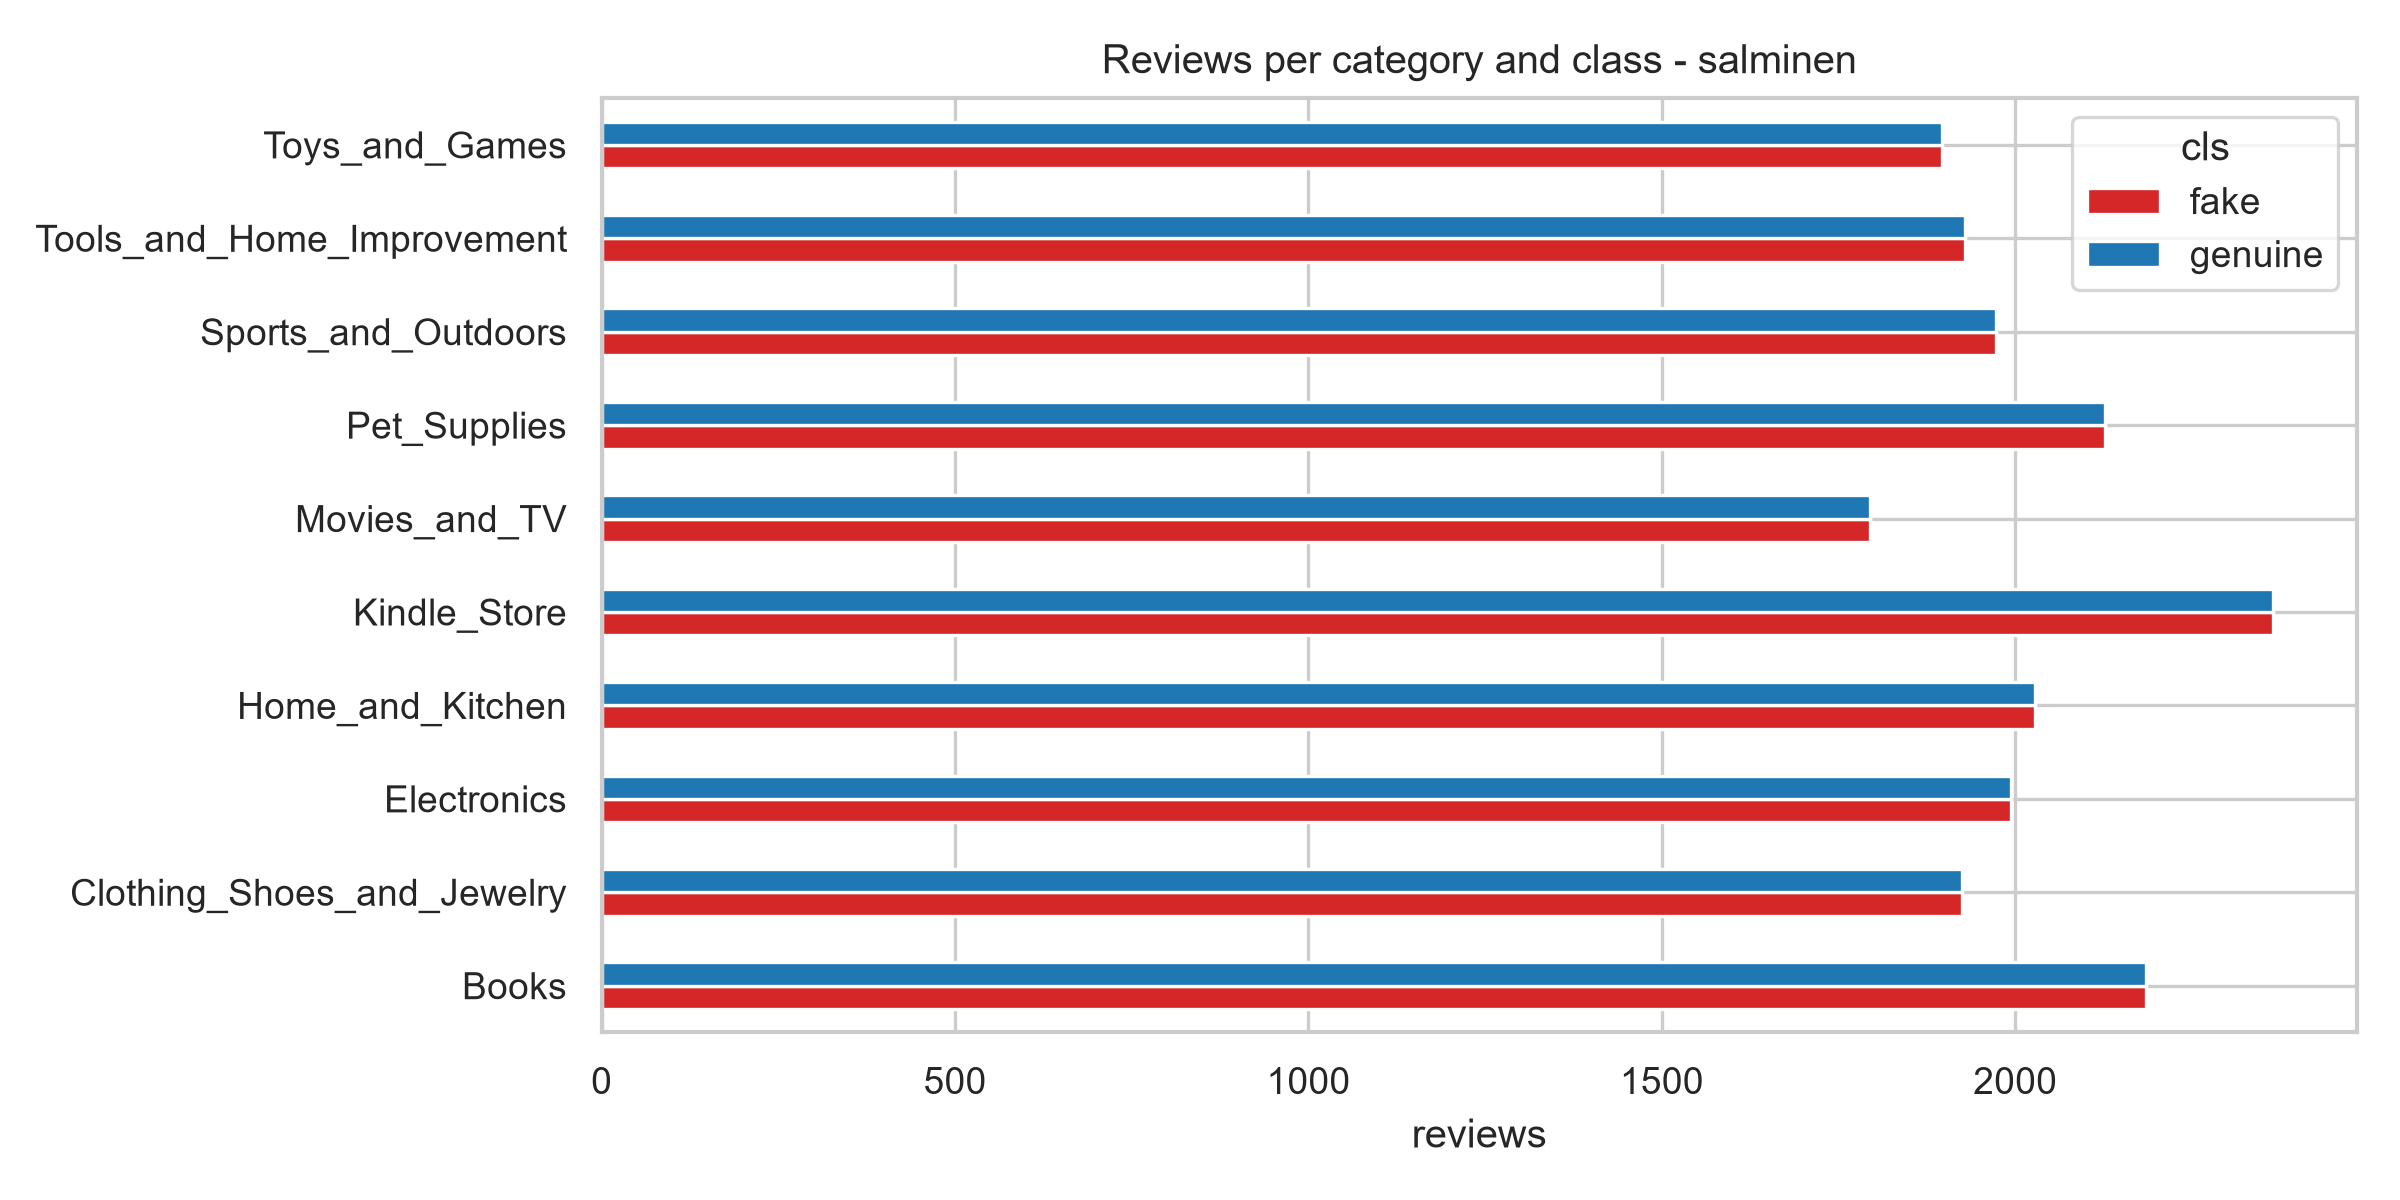

**top_unigrams**

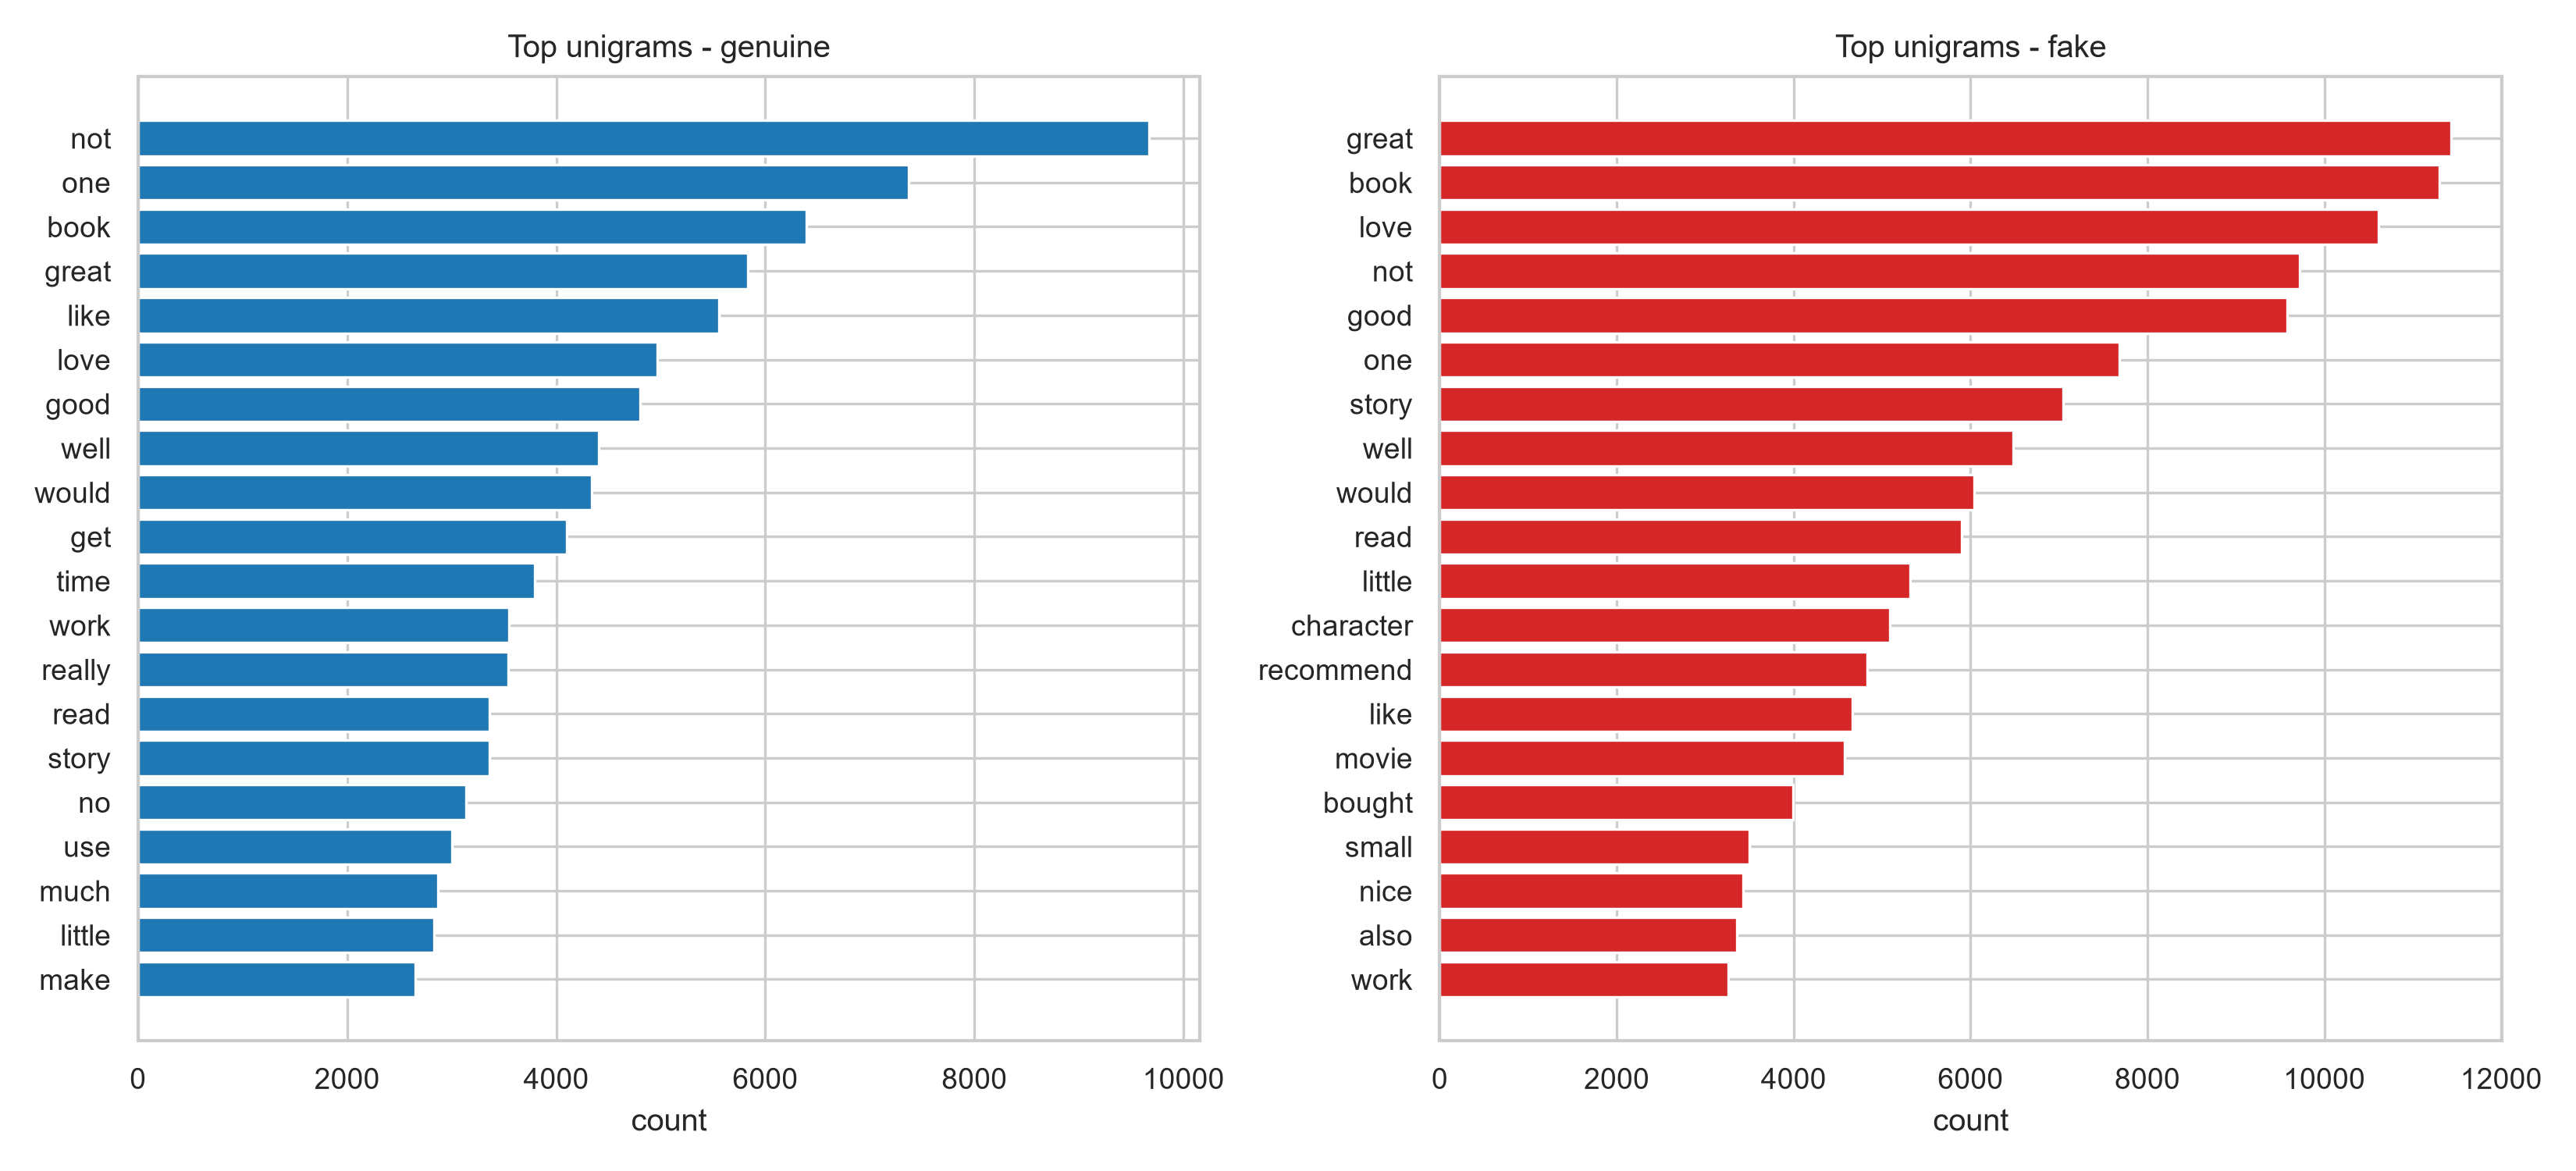

**top_bigrams**

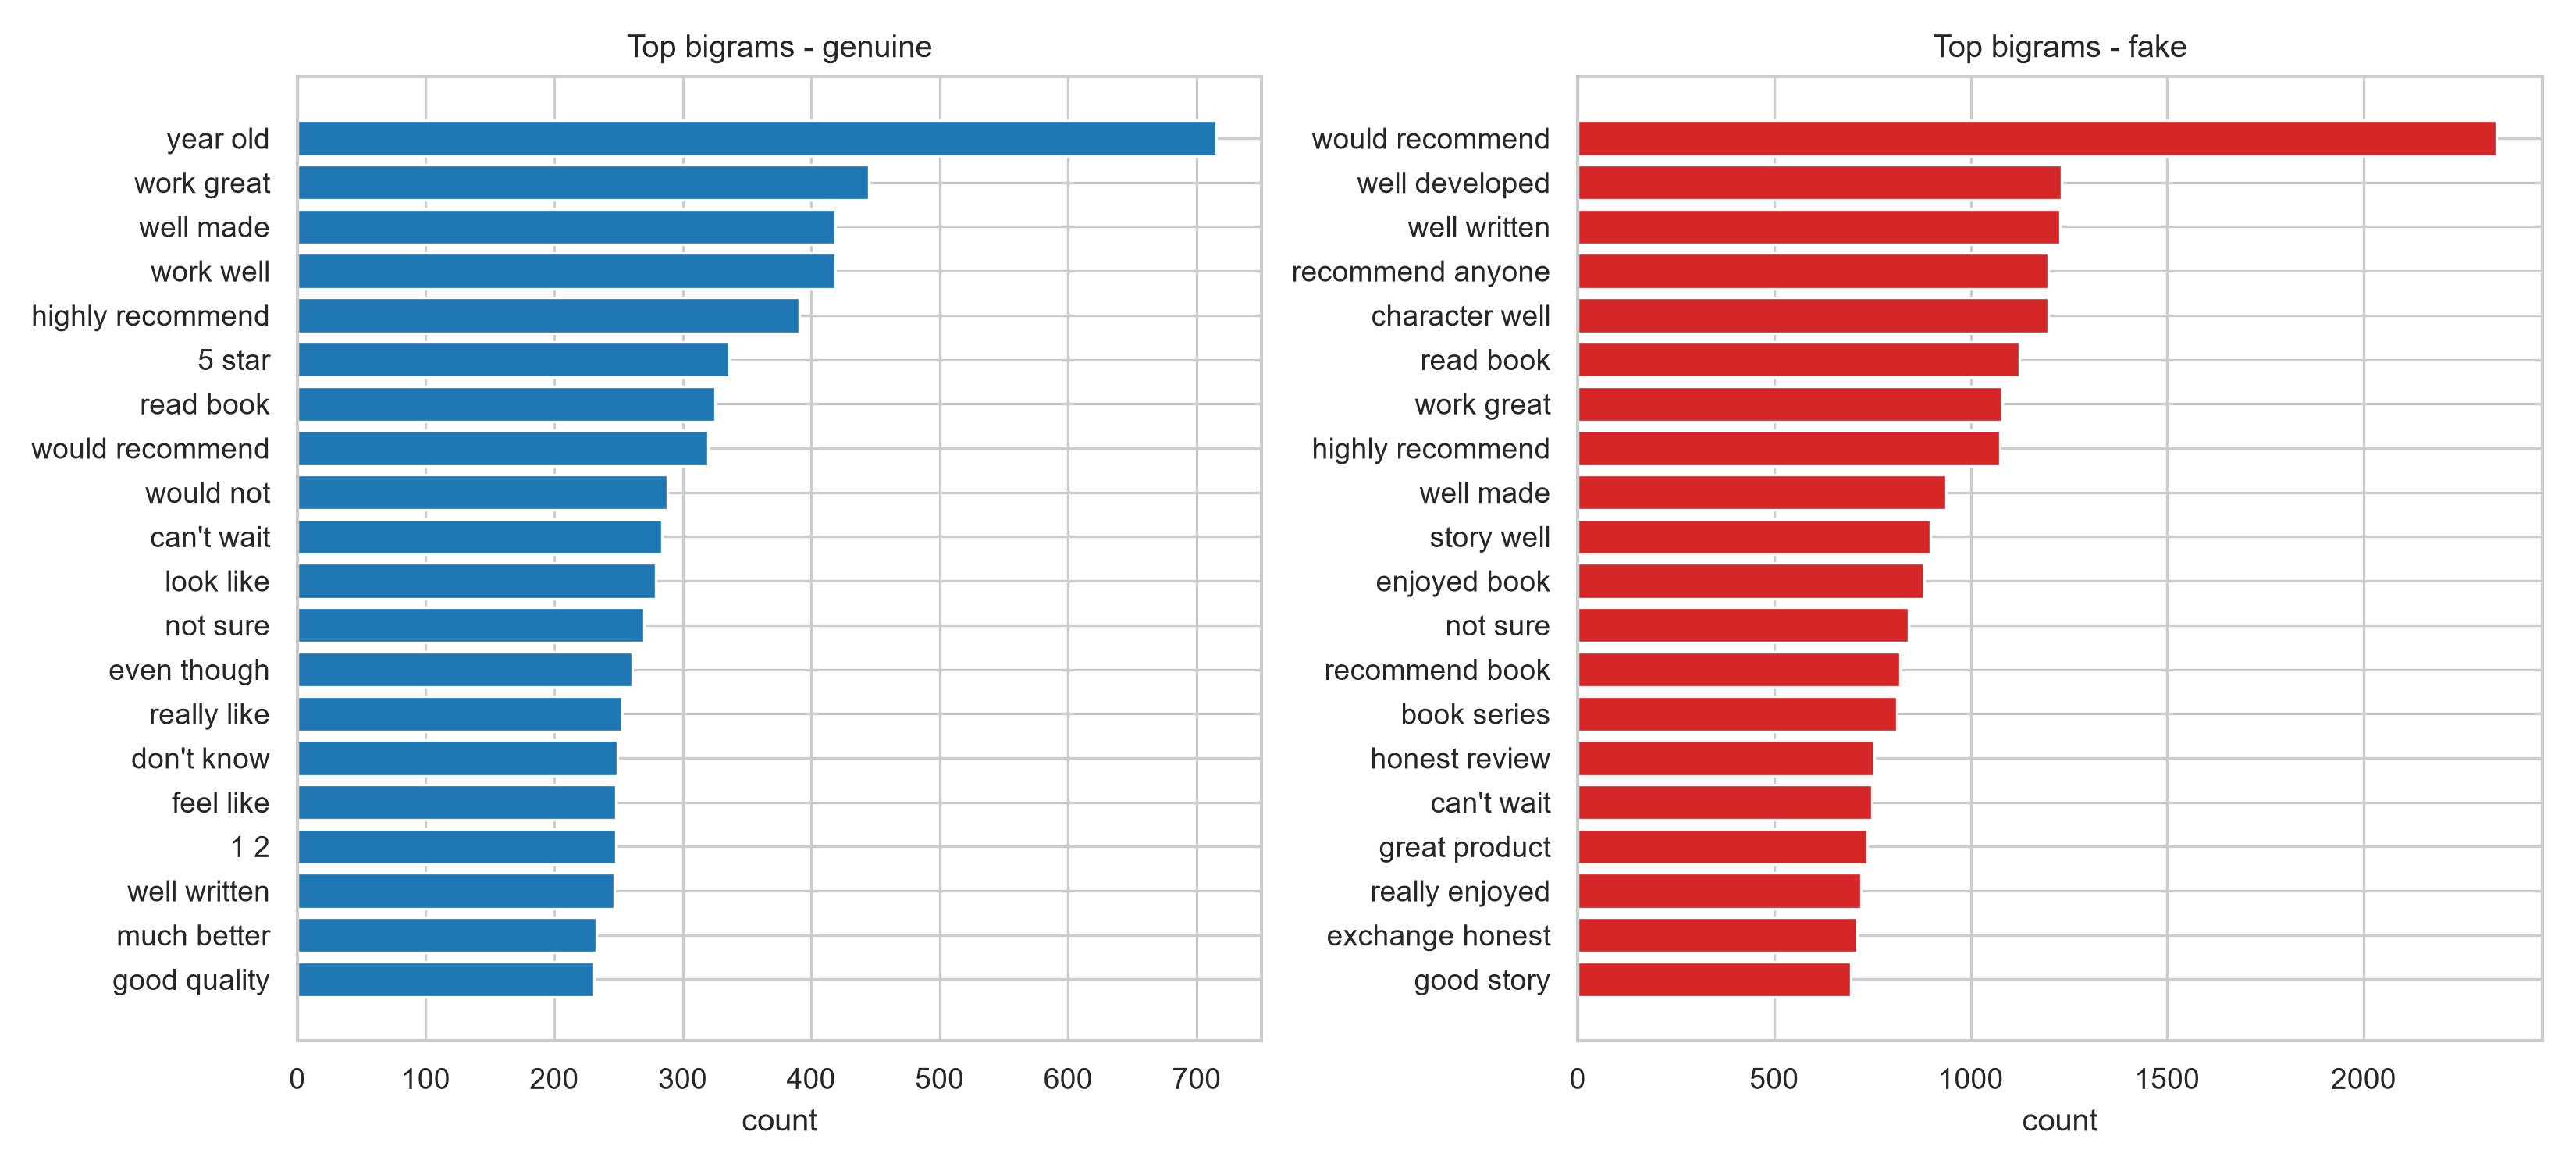

**wordclouds**

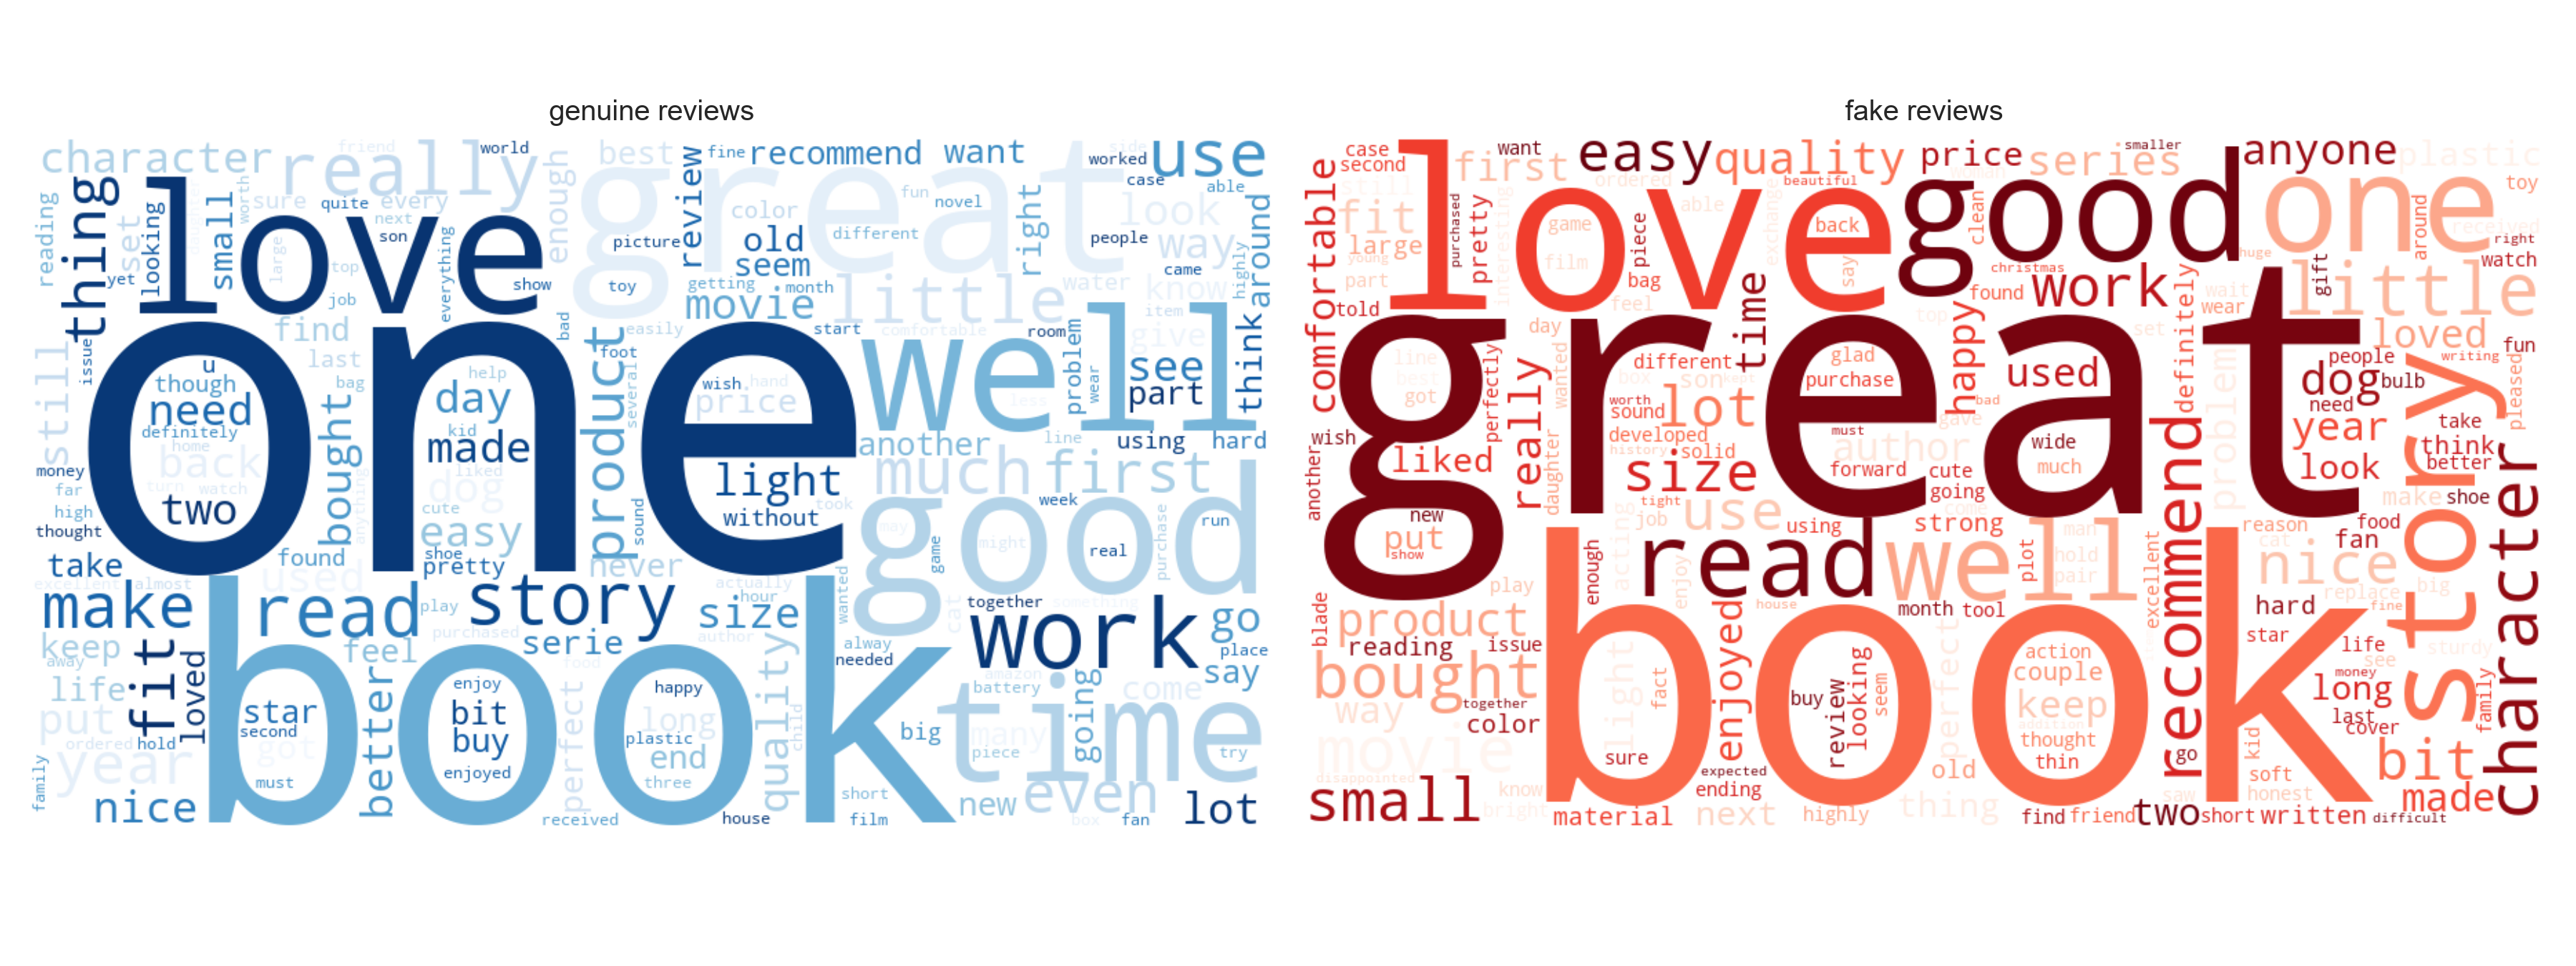

**style_signals**

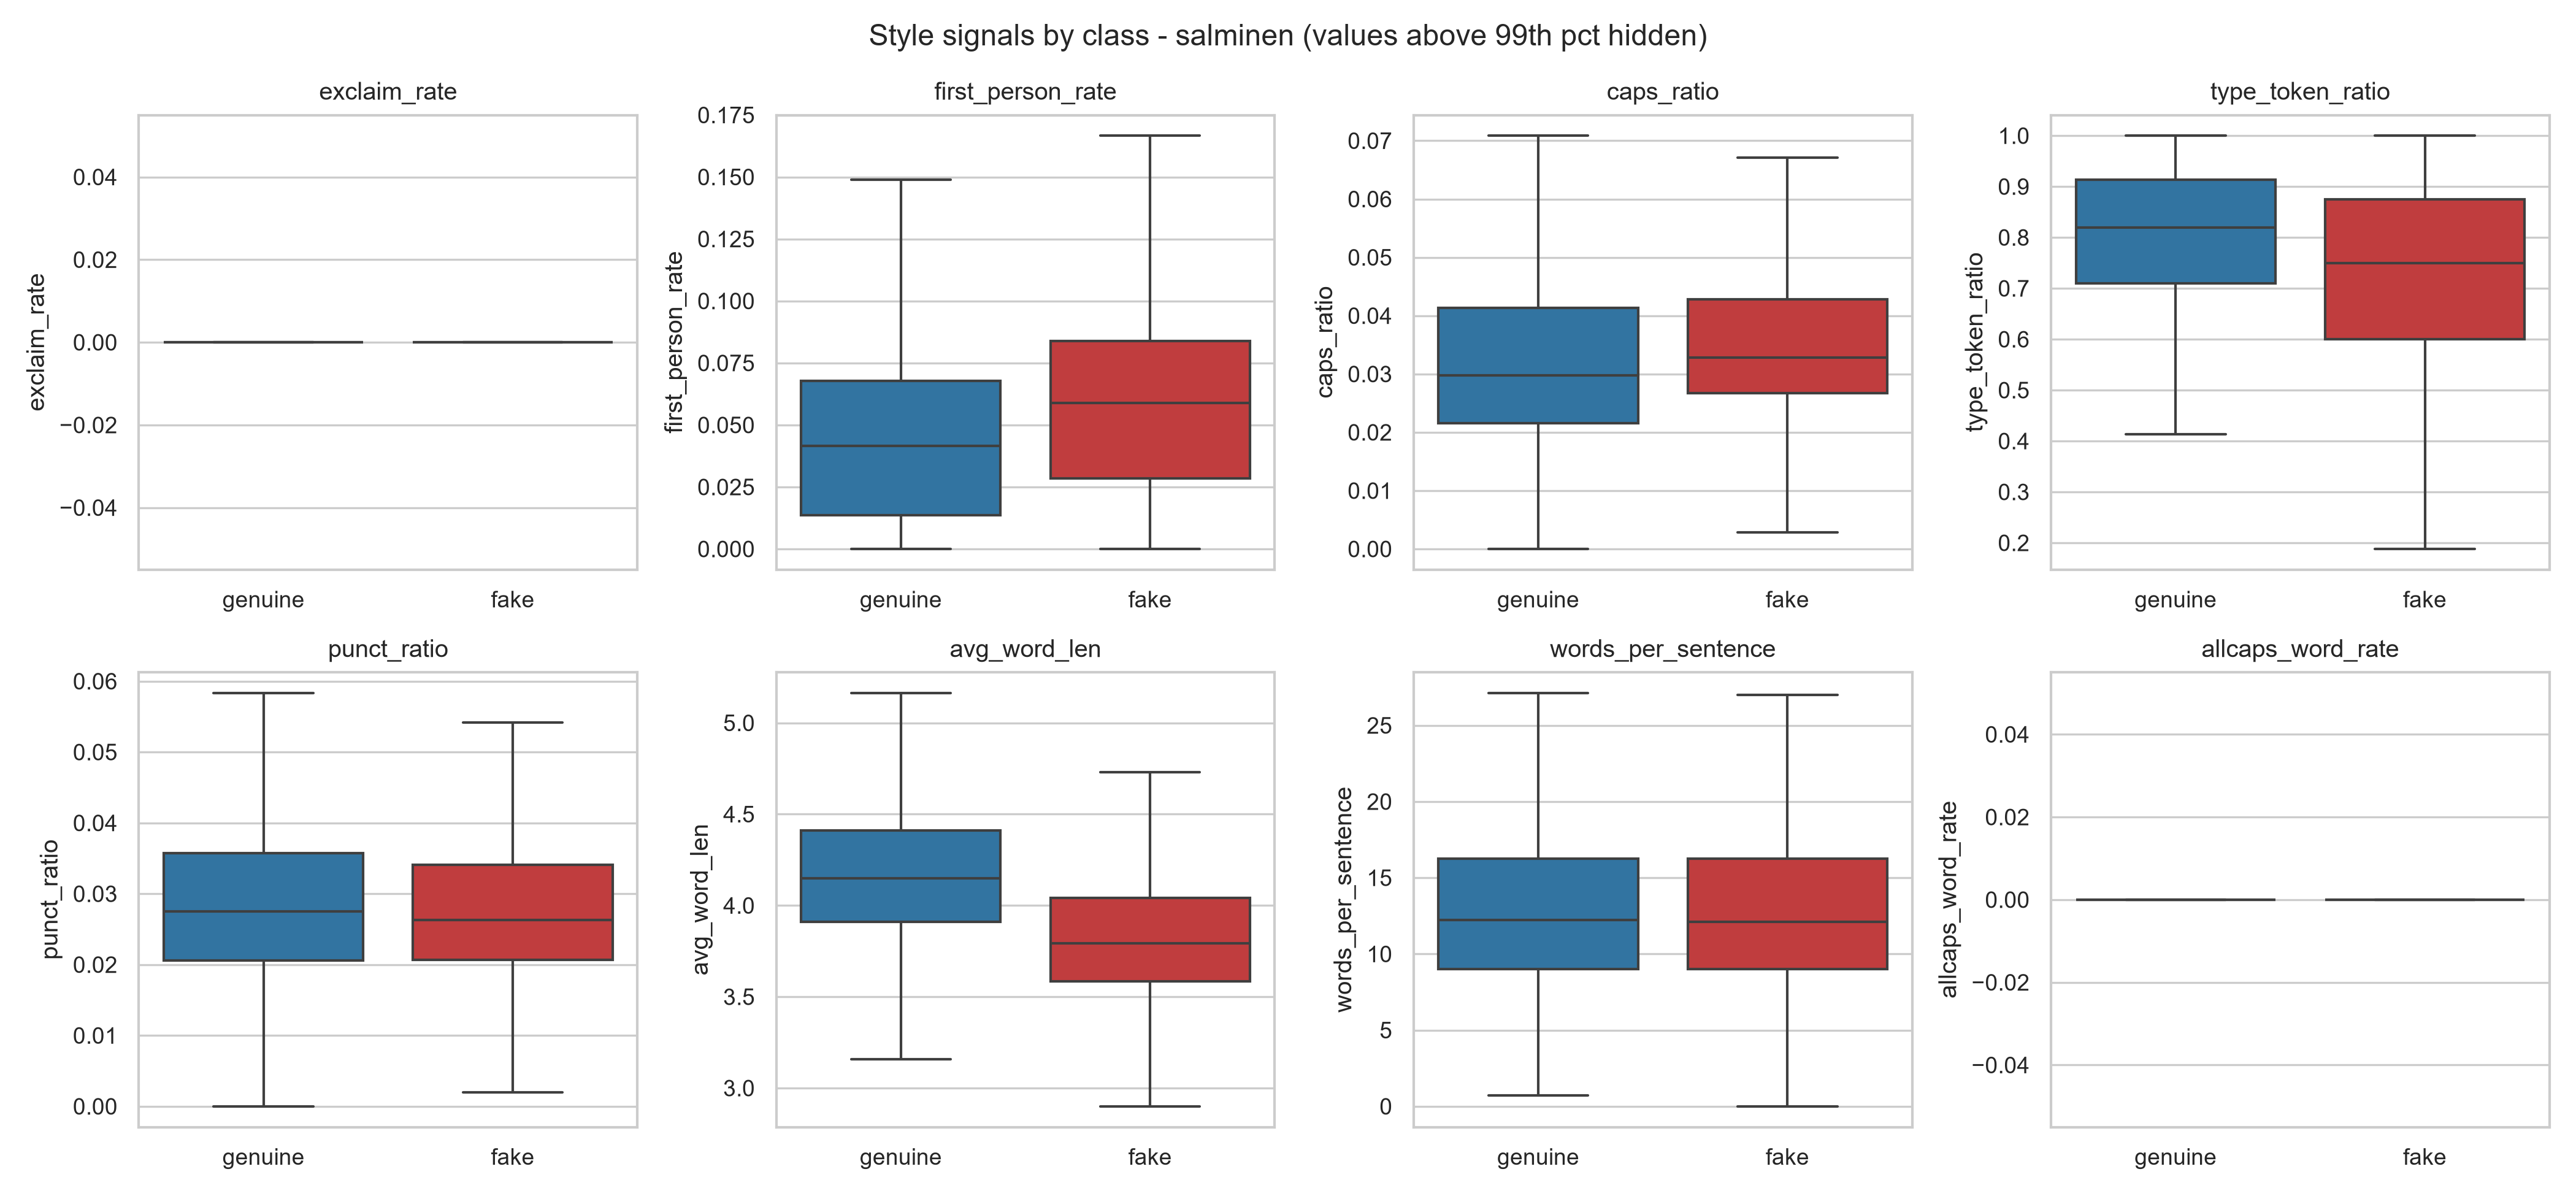

In [5]:
for name in ["class_balance", "length_by_class", "rating_by_class", "category_by_class",
             "top_unigrams", "top_bigrams", "wordclouds", "style_signals"]:
    display(Markdown(f"**{name}**")); display(Image(f"results/plots/eda/salminen_{name}.png", width=850))

In [6]:
import pandas as pd
display(pd.read_csv("results/plots/eda/salminen_style_means.csv", index_col=0))
display(pd.read_csv("results/plots/eda/salminen_distinctive_words.csv").head(15))

,fake,genuine
n_chars,302.6461,393.2066
n_words,61.9663,73.9572
avg_word_len,3.8450,4.1880
n_sentences,5.4053,5.7060
words_per_sentence,13.3636,13.3774
exclaim_rate,0.0064,0.0117
question_rate,0.0003,0.0009
punct_ratio,0.0289,0.0298
first_person_rate,0.0597,0.0459
caps_ratio,0.0409,0.0387


,fake_words,fake_log_odds,genuine_words,genuine_log_odds
0,trs,5.13,among,-4.08
1,treme,4.58,therefore,-3.79
2,tootlemania,4.10,thats,-3.74
3,32d,3.98,factor,-3.74
4,80a,3.97,accept,-3.67
5,g17,3.80,extended,-3.67
6,kinsella,3.77,velcro,-3.66
7,rosanna,3.70,anti,-3.64
8,32oz,3.61,closer,-3.60
9,schlage,3.56,spread,-3.56


## Ott (hotels, human-written deceptive reviews)

21:17:28 | INFO    | eda | saved results\plots\eda\ott_class_balance.png


21:17:30 | INFO    | eda | saved results\plots\eda\ott_length_by_class.png


21:17:31 | INFO    | eda | saved results\plots\eda\ott_category_by_class.png


21:17:35 | INFO    | eda | saved results\plots\eda\ott_top_unigrams.png


21:17:38 | INFO    | eda | saved results\plots\eda\ott_top_bigrams.png


21:17:49 | INFO    | eda | saved results\plots\eda\ott_wordclouds.png


21:17:54 | INFO    | eda | saved results\plots\eda\ott_style_signals.png


{
 "n_reviews": 1600,
 "class_counts": {
  "fake": 800,
  "genuine": 800
 },
 "words_median": {
  "fake": 137.0,
  "genuine": 145.0
 },
 "words_mean": {
  "fake": 161.8,
  "genuine": 169.2
 }
}


**class_balance**

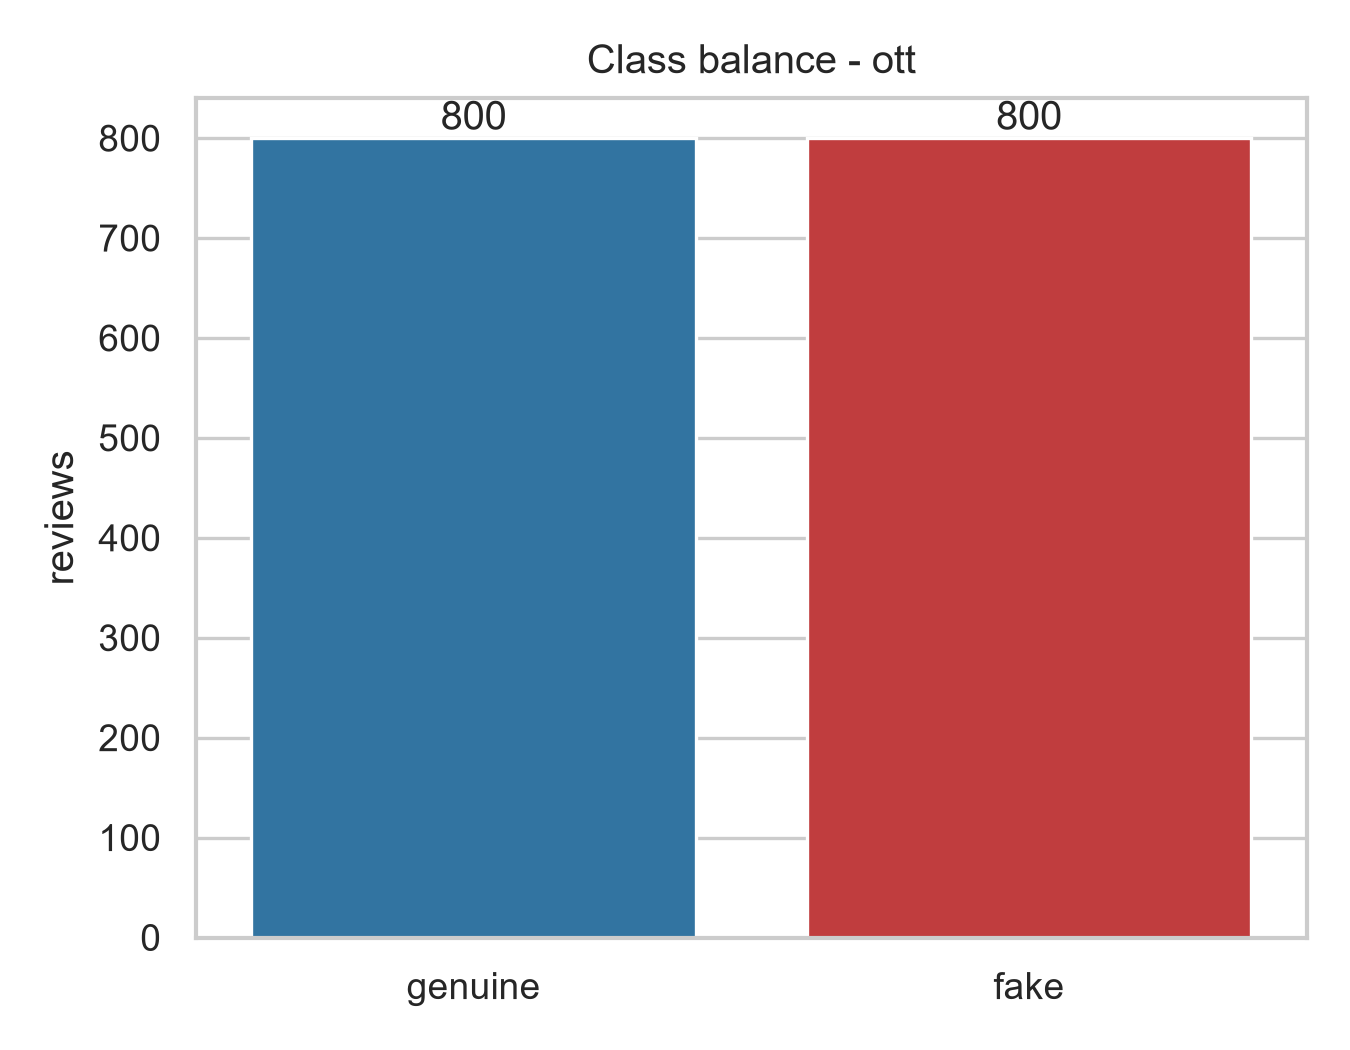

**length_by_class**

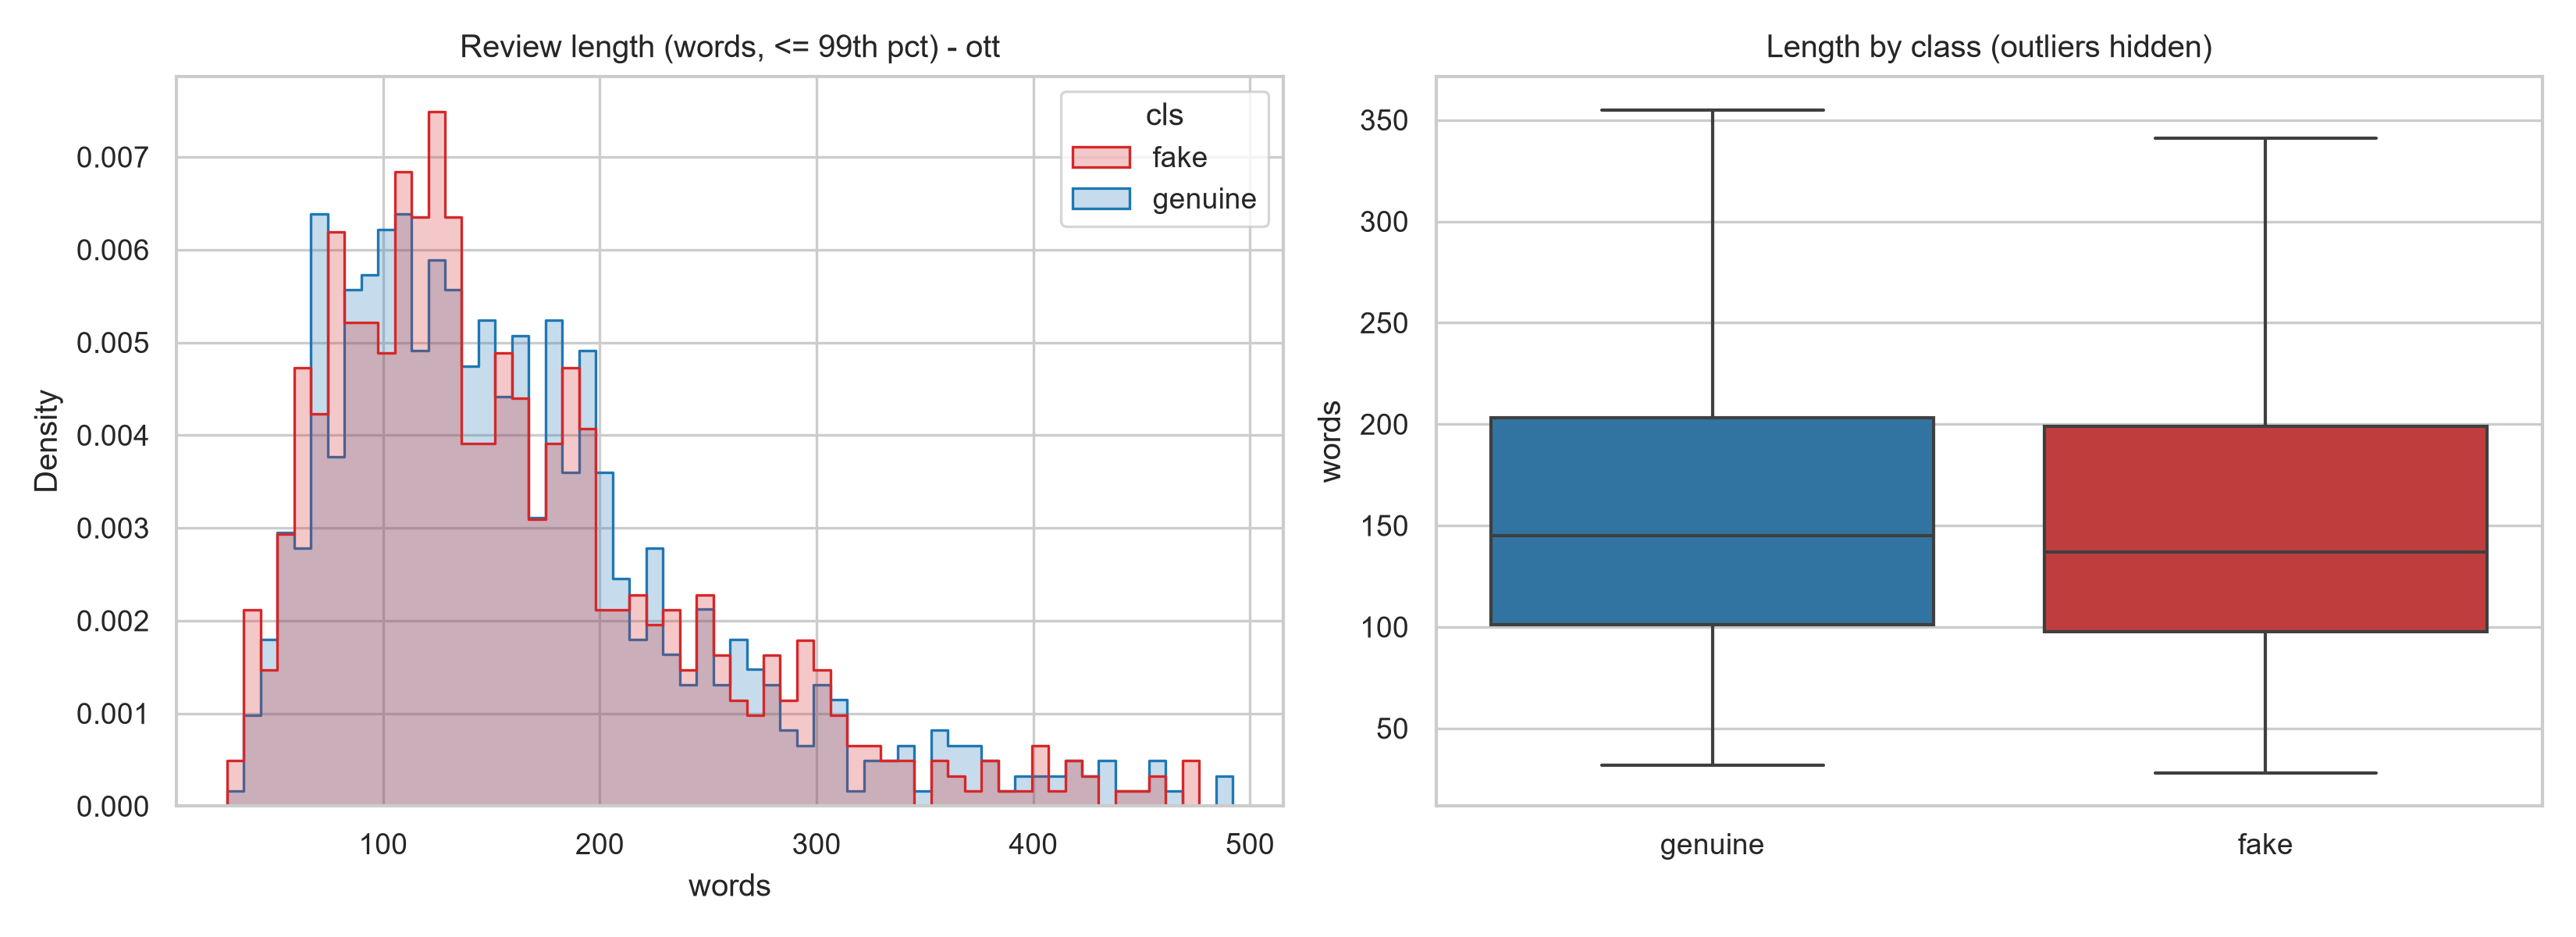

**top_unigrams**

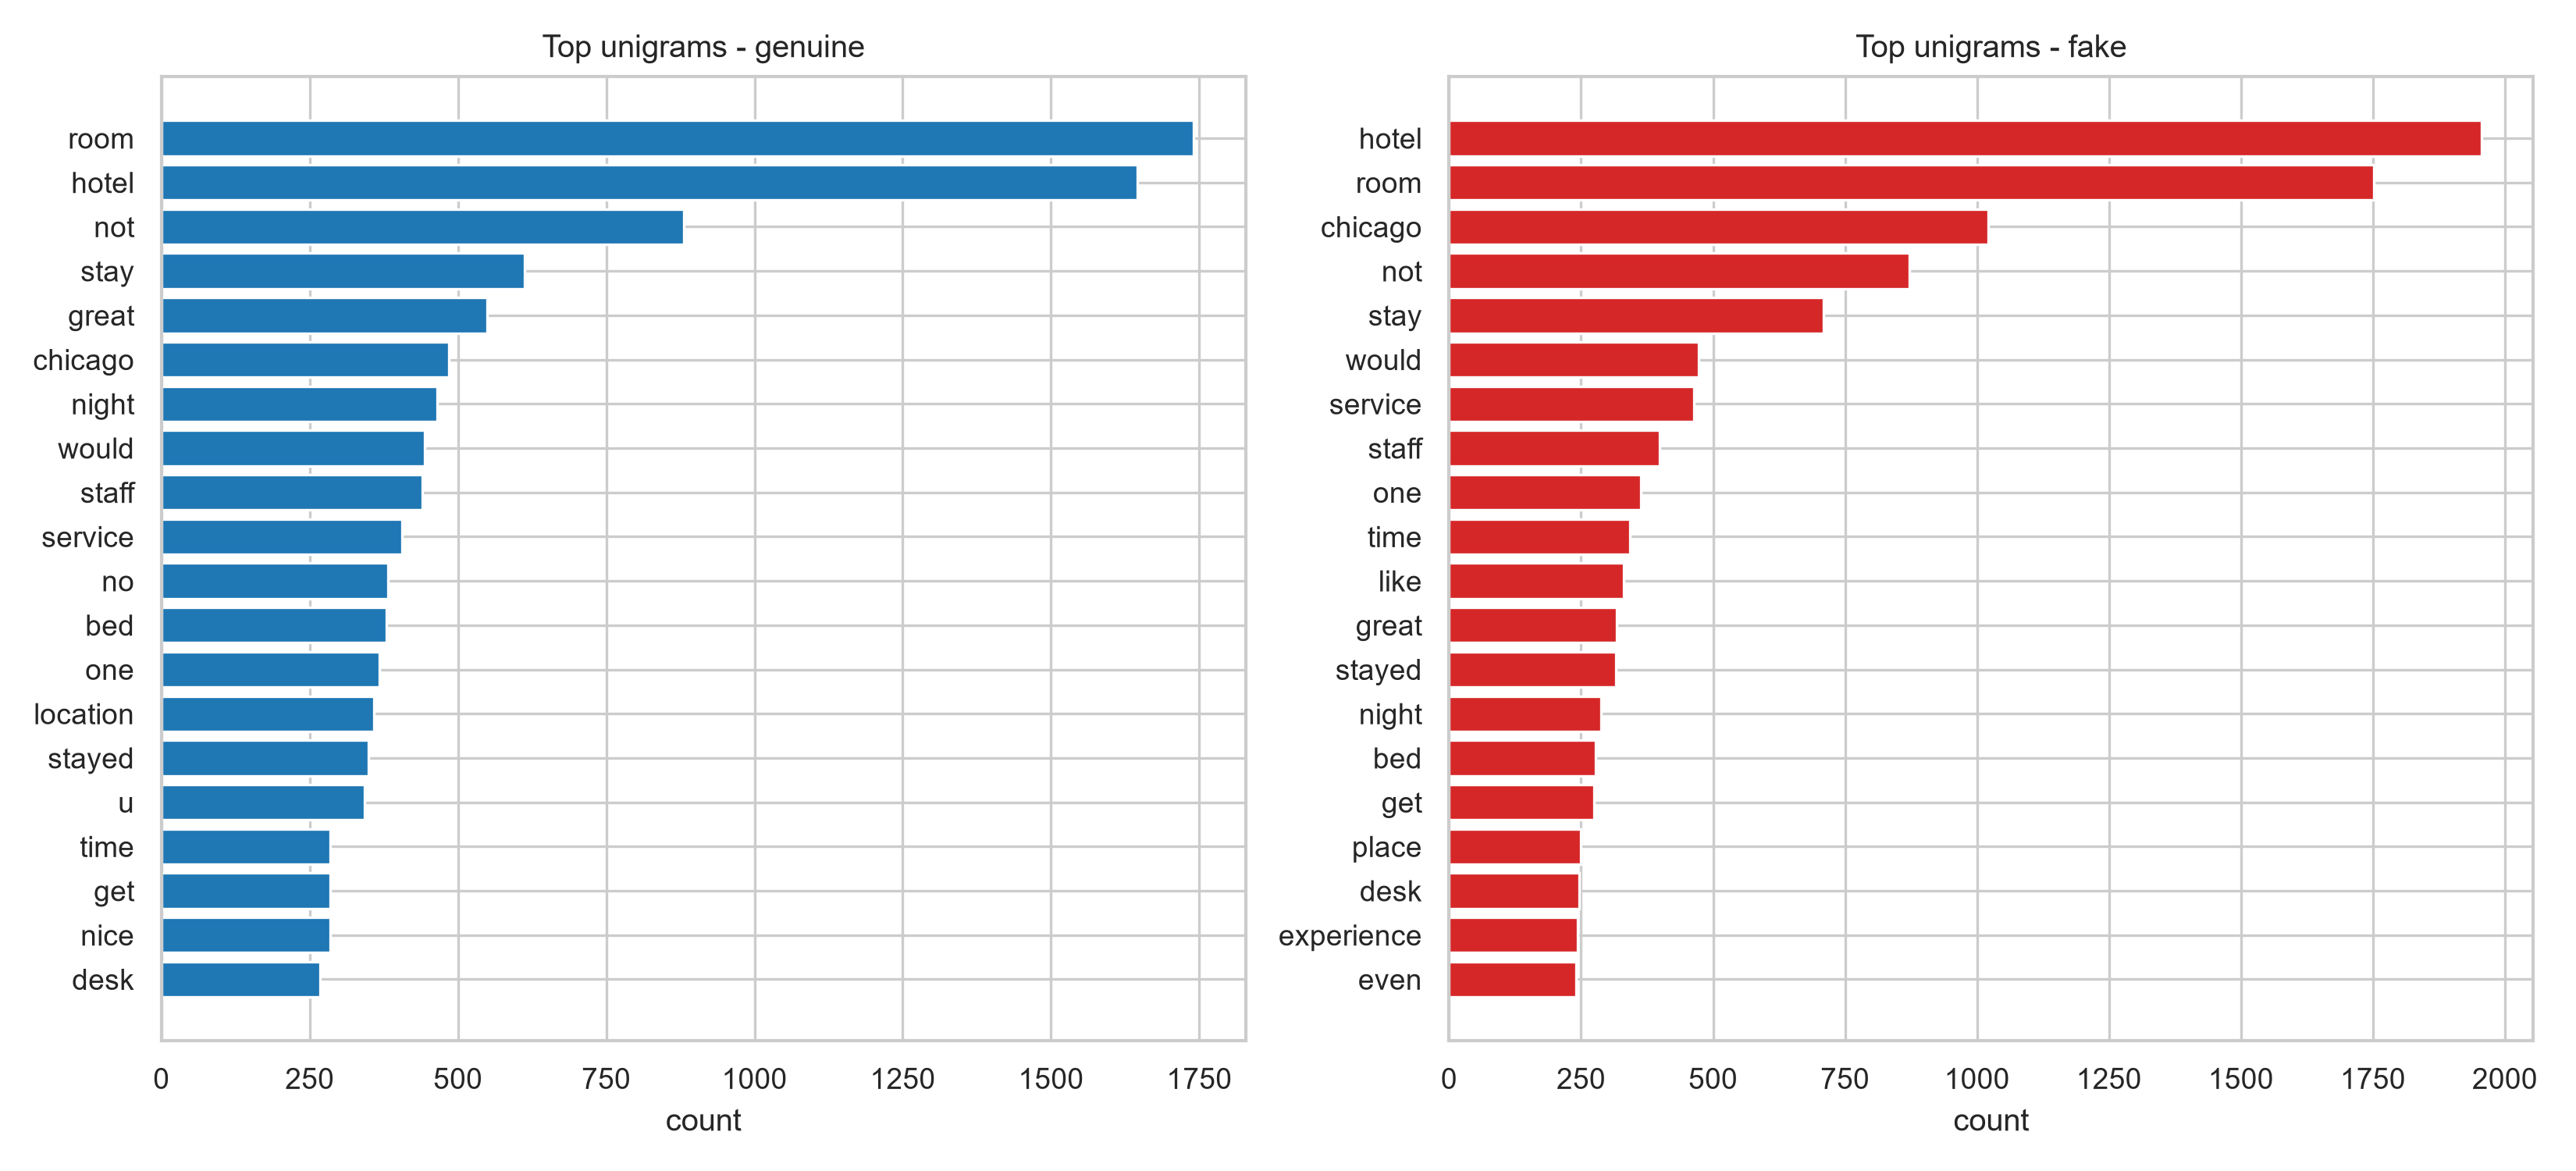

**wordclouds**

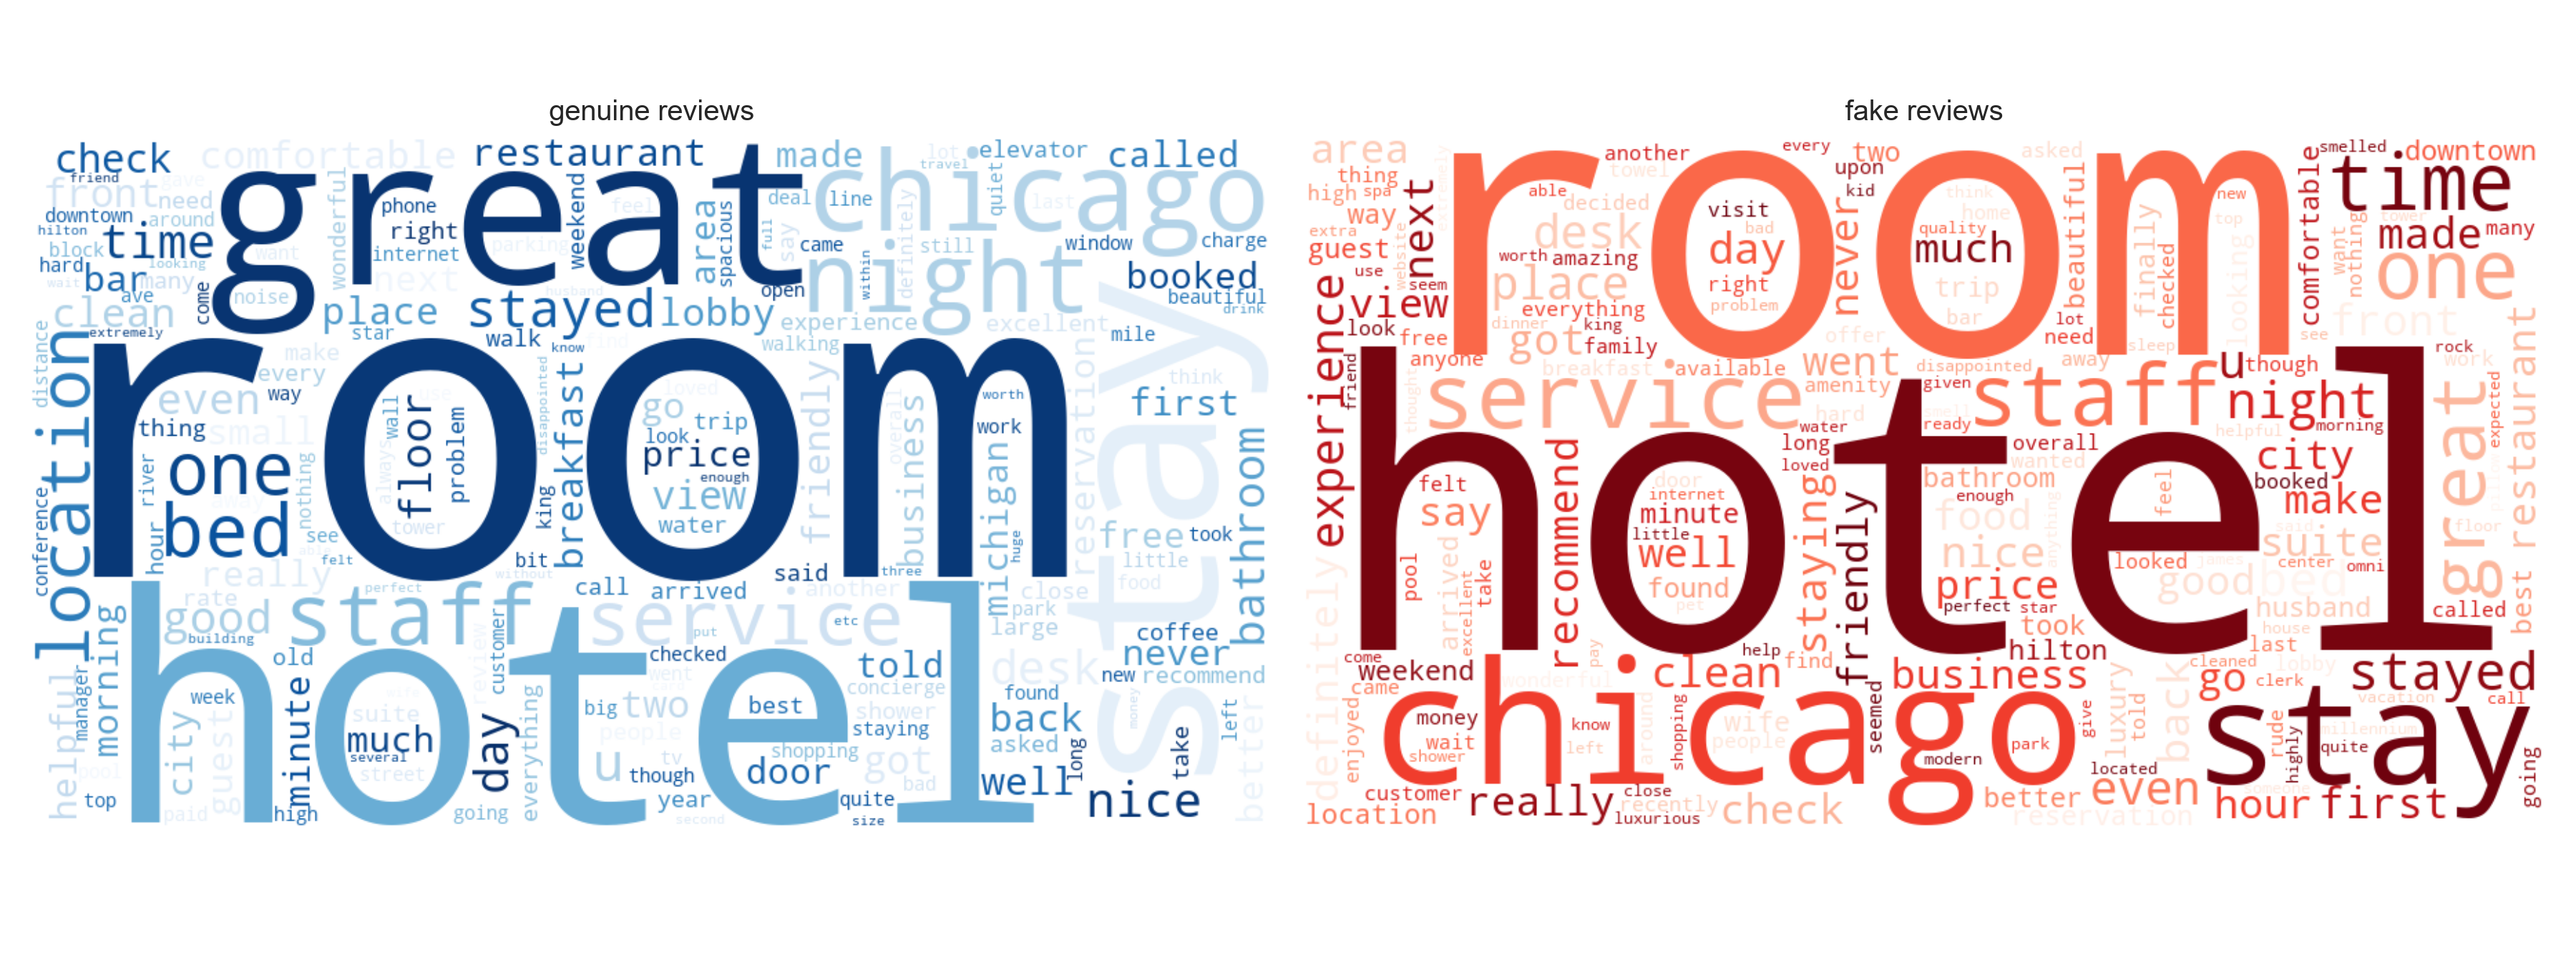

**style_signals**

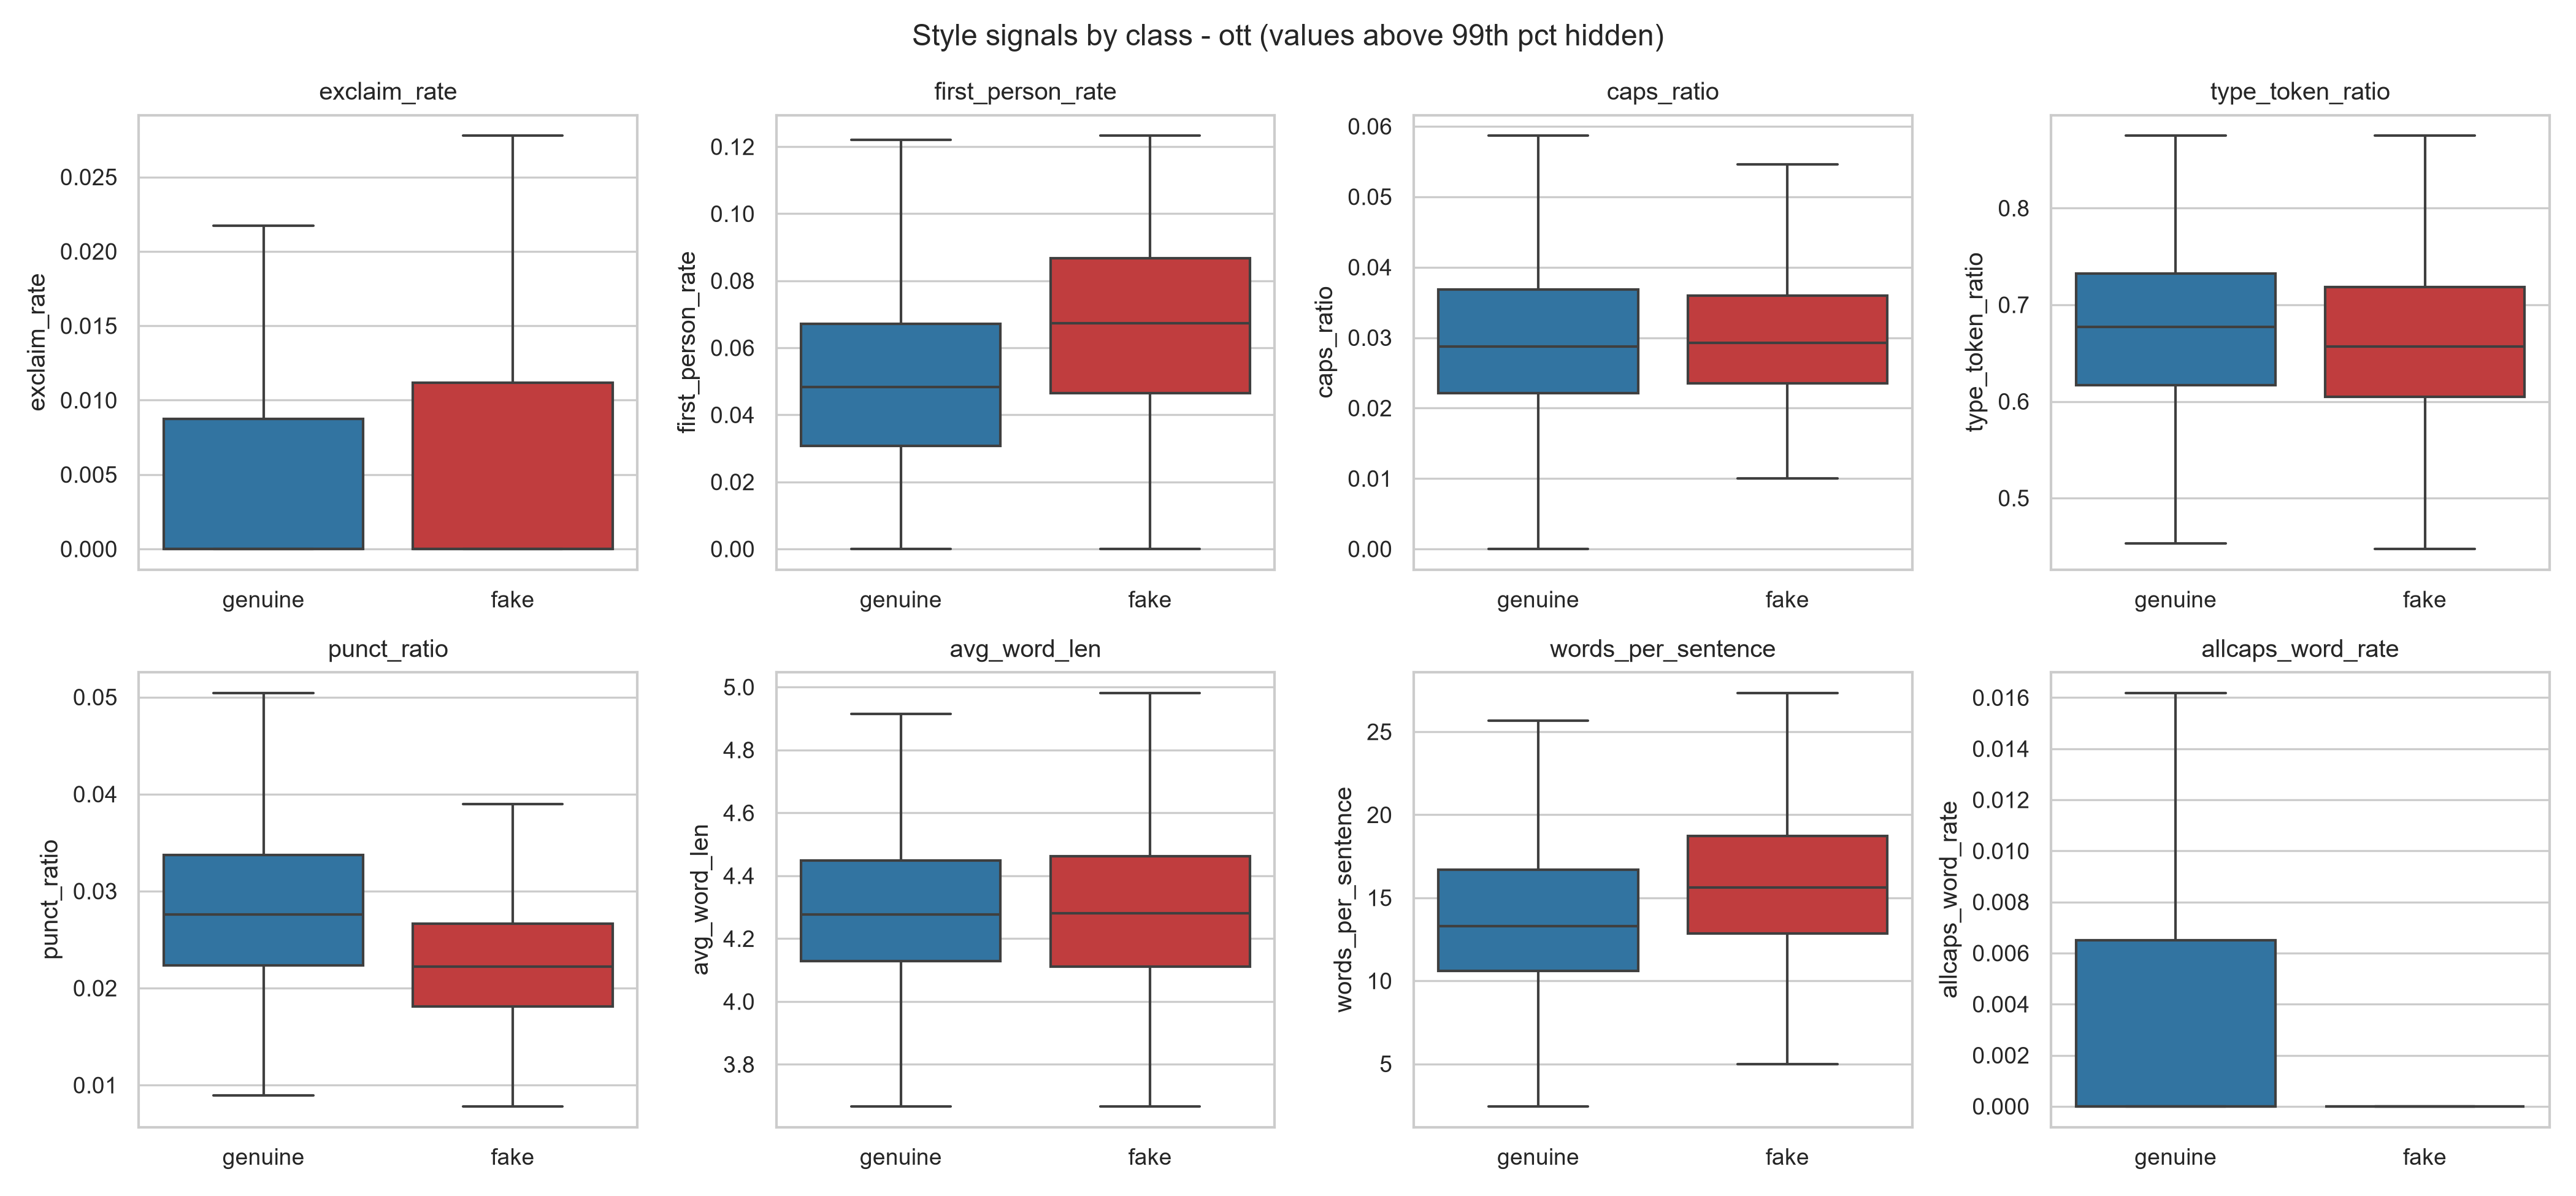

In [7]:
stats_ott = run_eda("ott", cfg)
print(json.dumps({k: stats_ott[k] for k in ["n_reviews", "class_counts", "words_median", "words_mean"]}, indent=1))
for name in ["class_balance", "length_by_class", "top_unigrams", "wordclouds", "style_signals"]:
    display(Markdown(f"**{name}**")); display(Image(f"results/plots/eda/ott_{name}.png", width=850))

In [8]:
display(pd.read_csv("results/plots/eda/ott_style_means.csv", index_col=0))

,fake,genuine
n_chars,790.5975,819.4925
n_words,147.2388,151.6400
avg_word_len,4.3035,4.3027
n_sentences,9.3875,11.8550
words_per_sentence,16.0877,14.6721
exclaim_rate,0.0082,0.0071
question_rate,0.0004,0.0011
punct_ratio,0.0228,0.0291
first_person_rate,0.0662,0.0494
caps_ratio,0.0320,0.0312


Observations are written up (from these exact plots and numbers) in [`results/eda_summary.md`](../results/eda_summary.md).